### **Импорты и загрузка данных**

Пути к данным указаны для запуска из папки `your-sollution`.


In [ ]:
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

Matplotlib is building the font cache; this may take a moment.


In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

with np.load('../dataset/task3_1/train.npz', allow_pickle=False) as train:
    images = train['images']
    y = train['prediction'].reshape(-1)
    label_names = train['label_names']

with np.load('../dataset/task3_1/test_features.npz', allow_pickle=False) as test:
    test_images = test['images']
    test_ids = test['image_id']

class_ids = np.arange(9)
class_codes = ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
print('train:', images.shape, ' test_features:', test_images.shape)
print('Тип пикселей:', images.dtype, 'диапазон:', (images.min(), images.max()))
print('PyTorch:', torch.__version__)


train: (7200, 28, 28, 3)  test_features: (1800, 28, 28, 3)
Тип пикселей: uint8 диапазон: (np.uint8(0), np.uint8(255))
PyTorch: 2.15.0


In [3]:
assert images.shape[1:] == test_images.shape[1:] == (28, 28, 3)
assert images.dtype == test_images.dtype == np.uint8
assert len(y) == len(images) and np.array_equal(np.unique(y), class_ids)
assert len(test_ids) == len(test_images) and len(np.unique(test_ids)) == len(test_ids)

class_table = pd.DataFrame({
    'класс': class_ids,
    'код': class_codes,
    'ткань': label_names,
    'число изображений': np.bincount(y, minlength=9),
})
class_table['доля'] = (class_table['число изображений'] / len(y)).round(3)
class_table


,класс,код,ткань,число изображений,доля
0,0,ADI,adipose,750,0.104
1,1,BACK,background,761,0.106
2,2,DEB,debris,829,0.115
3,3,LYM,lymphocytes,832,0.116
4,4,MUC,mucus,641,0.089
5,5,MUS,smooth muscle,974,0.135
6,6,NORM,normal colon mucosa,631,0.088
7,7,STR,cancer-associated stroma,752,0.104
8,8,TUM,colorectal adenocarcinoma epithelium,1030,0.143


### **Примеры изображений и баланс классов**


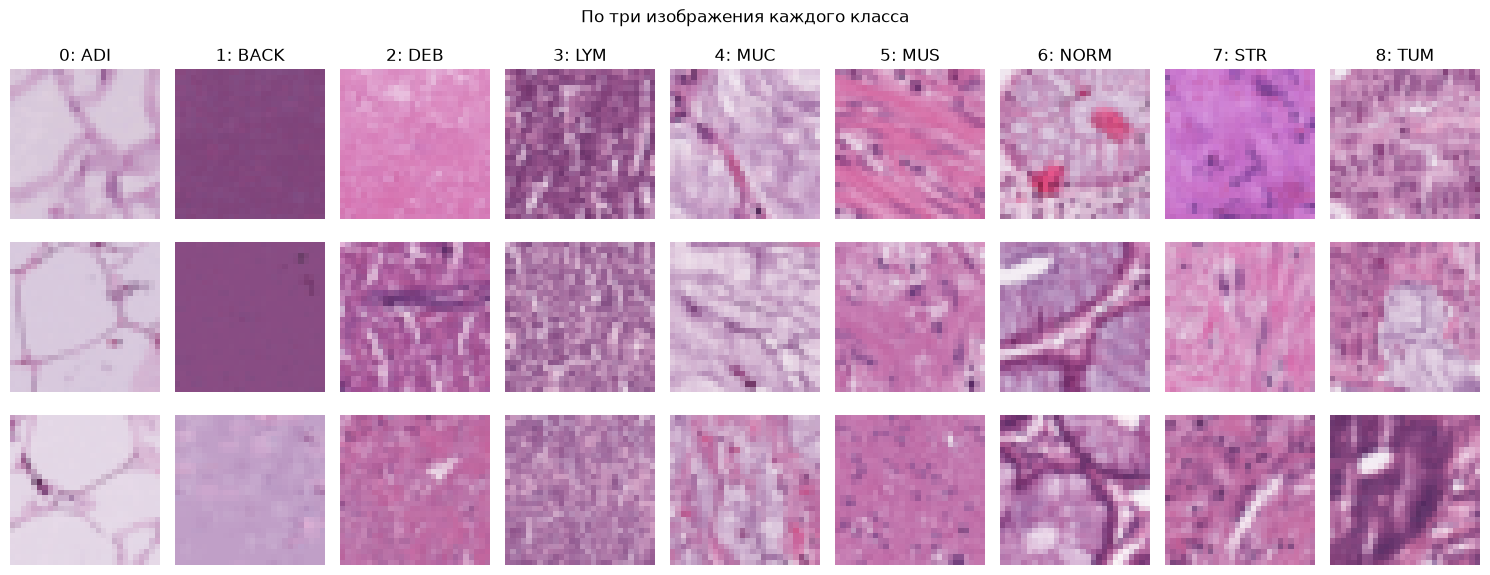

In [4]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 9, figsize=(15, 6))
for class_id in class_ids:
    indices = rng.choice(np.flatnonzero(y == class_id), size=3, replace=False)
    for row, idx in enumerate(indices):
        axes[row, class_id].imshow(images[idx])
        axes[row, class_id].axis('off')
    axes[0, class_id].set_title(f'{class_id}: {class_codes[class_id]}')
plt.suptitle('По три изображения каждого класса')
plt.tight_layout()
plt.show()


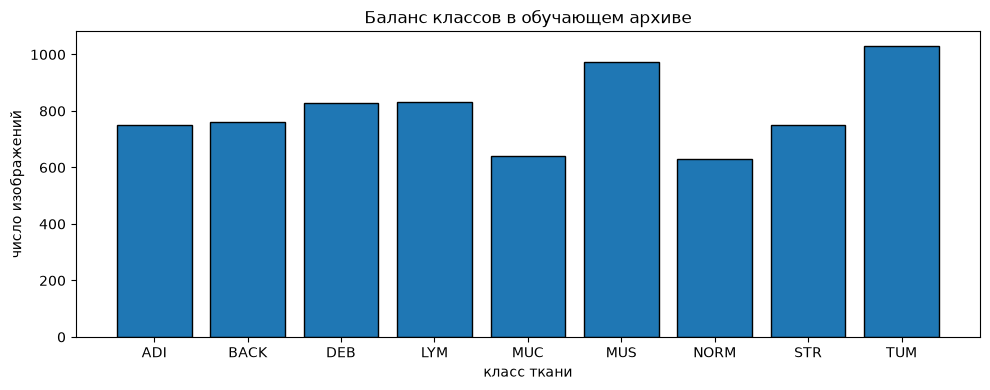

Отношение самого частого класса к самому редкому: 1.63


In [5]:
counts = class_table['число изображений'].to_numpy()
plt.figure(figsize=(10, 4))
plt.bar(class_codes, counts, edgecolor='black')
plt.xlabel('класс ткани')
plt.ylabel('число изображений')
plt.title('Баланс классов в обучающем архиве')
plt.tight_layout()
plt.show()
print('Отношение самого частого класса к самому редкому:', round(counts.max() / counts.min(), 2))


### **Стратифицированное разделение на train / val**

80% изображений используем для обучения, 20% — для валидации.
`test_features` содержит только отложенные признаки и в подборе модели не участвует.
Дисбаланс умеренный, поэтому оставляем обычную cross-entropy без весов;
качество контролируем по macro F1, который одинаково учитывает каждый класс.


In [6]:
train_idx, val_idx = train_test_split(
    np.arange(len(images)), test_size=0.2, stratify=y, random_state=SEED,
)
assert len(np.intersect1d(train_idx, val_idx)) == 0

split_counts = pd.DataFrame({
    'train': np.bincount(y[train_idx], minlength=9),
    'val': np.bincount(y[val_idx], minlength=9),
}, index=class_codes)
print('train:', len(train_idx), ' val:', len(val_idx), ' test_features:', len(test_images))
split_counts


train: 5760  val: 1440  test_features: 1800


,train,val
ADI,600,150
BACK,609,152
DEB,663,166
LYM,666,166
MUC,513,128
MUS,779,195
NORM,505,126
STR,601,151
TUM,824,206


### **Преобразование в тензоры и нормализация**

Меняем порядок осей с NHWC на NCHW, переводим пиксели в [0, 1],
затем применяем `(x - 0.5) / 0.5` к каждому RGB-каналу.
Получается диапазон [−1, 1]; параметры нормализации фиксированы условием.


In [7]:
def to_tensor(array):
    tensor = torch.from_numpy(array).permute(0, 3, 1, 2).contiguous().float() / 255.0
    return (tensor - 0.5) / 0.5

X = to_tensor(images)
X_submit = to_tensor(test_images)
targets = torch.from_numpy(y).long()

train_dataset = TensorDataset(X[train_idx], targets[train_idx])
val_dataset = TensorDataset(X[val_idx], targets[val_idx])
batch_size = 128
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
train_eval_loader = DataLoader(train_dataset, batch_size=batch_size)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(X_submit, batch_size=batch_size, shuffle=False)

print('Тензоры:', X.shape, 'диапазон:', (X.min().item(), X.max().item()))


Тензоры: torch.Size([7200, 3, 28, 28]) диапазон: (-1.0, 1.0)


### **CNN с девятью выходами**

Три свёрточных блока (32 → 64 → 128 каналов), BatchNorm и ReLU.
После двух первых блоков уменьшаем изображение вдвое через MaxPool,
после третьего — до 2 × 2 через AdaptiveAvgPool.
Классификатор: 512 → 128 → 9, с Dropout 0.3.
На выходе логиты: softmax уже входит в `CrossEntropyLoss`.


In [8]:
class TissueCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d((2, 2)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 2 * 2, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, 9),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = TissueCNN()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3,
)
print('Обучаемых параметров:', sum(p.numel() for p in model.parameters() if p.requires_grad))
model


Обучаемых параметров: 160521


TissueCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(2, 2))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0

### **Обучение и сохранение лучшего состояния**

Обучаем не более 30 эпох. Только на train случайно отражаем изображения
по горизонтали и вертикали. Используем Dropout и L2-регуляризацию;
при отсутствии улучшения macro F1 семь эпох подряд останавливаемся.
После каждой эпохи оцениваем train и val в режиме `eval`, без отражений.
Лучшие веса сохраняем в памяти по macro F1 на val и затем восстанавливаем.


In [9]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss = 0.0
    true_labels, predictions = [], []
    for inputs, labels in loader:
        logits = model(inputs)
        total_loss += criterion(logits, labels).item() * len(labels)
        true_labels.append(labels.cpu().numpy())
        predictions.append(logits.argmax(dim=1).cpu().numpy())
    true_labels = np.concatenate(true_labels)
    predictions = np.concatenate(predictions)
    return {
        'loss': total_loss / len(true_labels),
        'accuracy': accuracy_score(true_labels, predictions),
        'macro_f1': f1_score(true_labels, predictions, labels=class_ids, average='macro', zero_division=0),
    }, predictions


In [10]:
epochs, patience = 30, 7
history = []
best_f1, best_epoch, stale_epochs = -1.0, 0, 0
best_state = None

for epoch in range(1, epochs + 1):
    model.train()
    for inputs, labels in train_loader:
        for axis in (-1, -2):
            flip = torch.rand(len(inputs), 1, 1, 1) < 0.5
            inputs = torch.where(flip, inputs.flip(axis), inputs)
        optimizer.zero_grad()
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()

    train_metrics, _ = evaluate(train_eval_loader)
    val_metrics, _ = evaluate(val_loader)
    history.append({
        'epoch': epoch,
        **{f'train_{key}': value for key, value in train_metrics.items()},
        **{f'val_{key}': value for key, value in val_metrics.items()},
    })
    scheduler.step(val_metrics['macro_f1'])

    if val_metrics['macro_f1'] > best_f1:
        best_f1, best_epoch = val_metrics['macro_f1'], epoch
        best_state = deepcopy(model.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1

    print(f"Эпоха {epoch:02d}: train loss = {train_metrics['loss']:.3f}, "
          f"val loss = {val_metrics['loss']:.3f}, val accuracy = {val_metrics['accuracy']:.3f}, "
          f"val macro F1 = {val_metrics['macro_f1']:.3f}", flush=True)
    if stale_epochs >= patience:
        print('Ранняя остановка: качество не улучшалось', patience, 'эпох.')
        break

model.load_state_dict(best_state)
history = pd.DataFrame(history)
print(f'Восстановлена эпоха {best_epoch}, val macro F1 = {best_f1:.3f}')


Эпоха 01: train loss = 1.435, val loss = 1.433, val accuracy = 0.504, val macro F1 = 0.444


Эпоха 02: train loss = 0.777, val loss = 0.805, val accuracy = 0.716, val macro F1 = 0.706


Эпоха 03: train loss = 0.643, val loss = 0.657, val accuracy = 0.774, val macro F1 = 0.770


Эпоха 04: train loss = 0.696, val loss = 0.712, val accuracy = 0.742, val macro F1 = 0.731


Эпоха 05: train loss = 0.657, val loss = 0.711, val accuracy = 0.748, val macro F1 = 0.744


Эпоха 06: train loss = 0.846, val loss = 0.919, val accuracy = 0.704, val macro F1 = 0.707


... (21 outputs left out)

Эпоха 28: train loss = 0.158, val loss = 0.261, val accuracy = 0.914, val macro F1 = 0.913


Эпоха 29: train loss = 0.175, val loss = 0.277, val accuracy = 0.903, val macro F1 = 0.902


Эпоха 30: train loss = 0.183, val loss = 0.286, val accuracy = 0.888, val macro F1 = 0.886


Восстановлена эпоха 28, val macro F1 = 0.913


### **Кривые обучения**


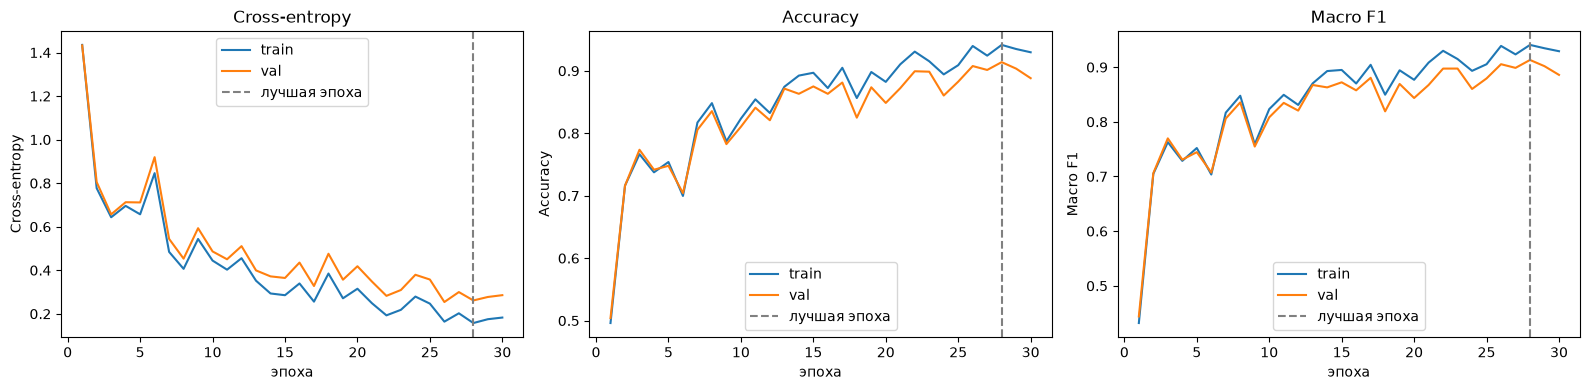

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes, ['loss', 'accuracy', 'macro_f1'], ['Cross-entropy', 'Accuracy', 'Macro F1']):
    ax.plot(history['epoch'], history[f'train_{metric}'], label='train')
    ax.plot(history['epoch'], history[f'val_{metric}'], label='val')
    ax.axvline(best_epoch, color='grey', linestyle='--', label='лучшая эпоха')
    ax.set_xlabel('эпоха')
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()


### **Оценка лучшей модели на валидации**


In [12]:
train_metrics, train_pred = evaluate(train_eval_loader)
val_metrics, val_pred = evaluate(val_loader)
pd.DataFrame([train_metrics, val_metrics], index=['train', 'val']).round(3)


,loss,accuracy,macro_f1
train,0.158,0.941,0.941
val,0.261,0.914,0.913


In [13]:
report = classification_report(
    y[val_idx], val_pred, labels=class_ids, target_names=class_codes,
    output_dict=True, zero_division=0,
)
class_report = pd.DataFrame(report).T.loc[class_codes].copy()
class_report['support'] = class_report['support'].astype(int)
class_report.round(3)


,precision,recall,f1-score,support
ADI,0.986,0.960,0.973,150
BACK,0.993,0.987,0.990,152
DEB,0.832,0.867,0.850,166
LYM,0.971,0.994,0.982,166
MUC,0.862,0.930,0.895,128
MUS,0.910,0.938,0.924,195
NORM,0.931,0.857,0.893,126
STR,0.838,0.788,0.812,151
TUM,0.906,0.893,0.900,206


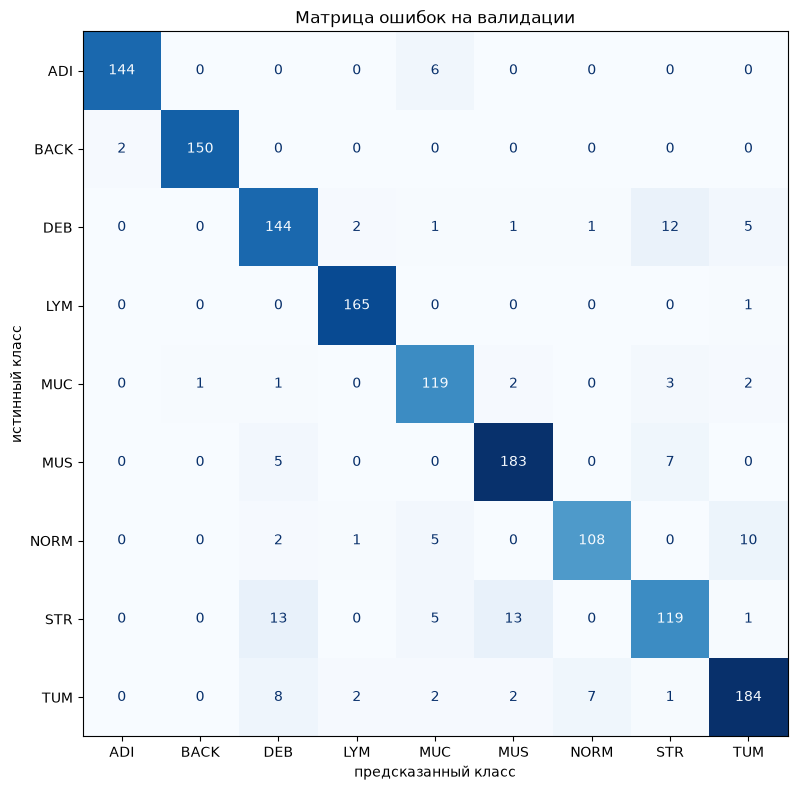

In [14]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y[val_idx], val_pred, labels=class_ids, display_labels=class_codes,
    cmap='Blues', ax=ax, colorbar=False,
)
ax.set_xlabel('предсказанный класс')
ax.set_ylabel('истинный класс')
ax.set_title('Матрица ошибок на валидации')
plt.tight_layout()
plt.show()


### **Примеры ошибок и слабые классы**


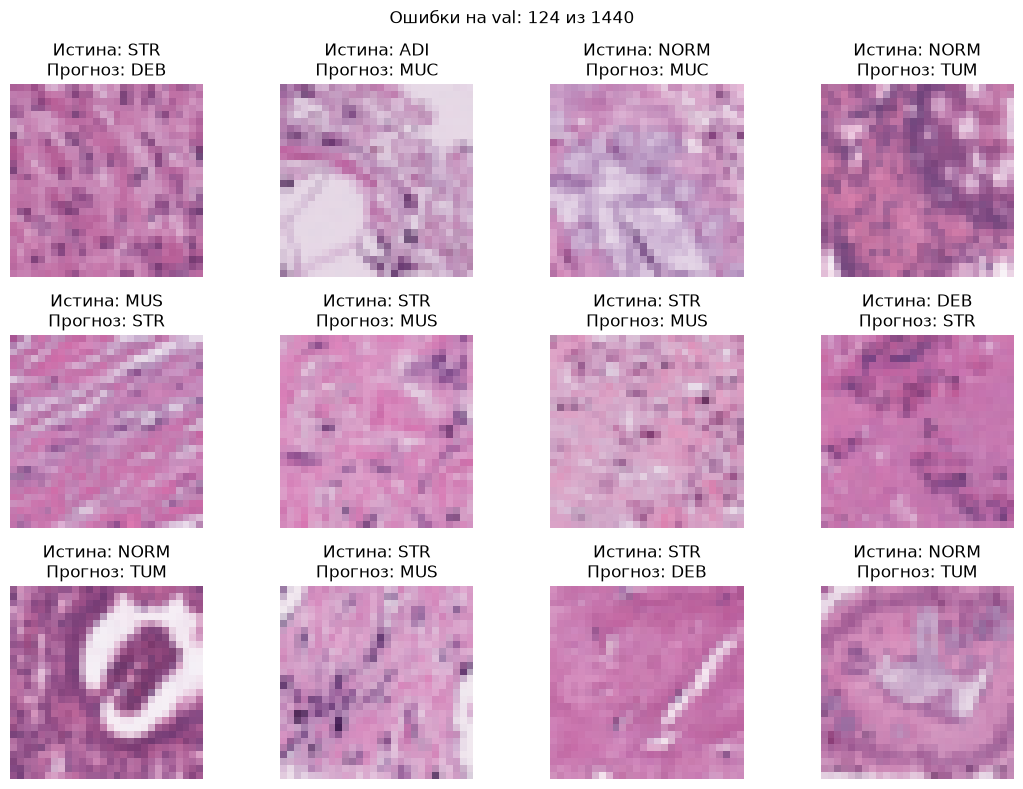

In [15]:
error_positions = np.flatnonzero(val_pred != y[val_idx])
rng = np.random.default_rng(SEED)
examples = rng.choice(error_positions, size=min(12, len(error_positions)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for ax in axes.ravel():
    ax.axis('off')
for ax, pos in zip(axes.ravel(), examples):
    ax.imshow(images[val_idx[pos]])
    ax.set_title(f'Истина: {class_codes[y[val_idx[pos]]]}\nПрогноз: {class_codes[val_pred[pos]]}')
plt.suptitle(f'Ошибки на val: {len(error_positions)} из {len(val_idx)}')
plt.tight_layout()
plt.show()


In [16]:
weak_classes = class_report.sort_values('f1-score').head(3)
weak_classes.round(3)


,precision,recall,f1-score,support
STR,0.838,0.788,0.812,151
DEB,0.832,0.867,0.850,166
NORM,0.931,0.857,0.893,126


### **Предсказания для test_features.npz**

Применяем восстановленную CNN в режиме `eval`, без аугментаций.
Порядок изображений сохраняется (`shuffle=False`), меток test_features нет.


In [17]:
model.eval()
test_predictions = []
with torch.no_grad():
    for inputs in test_loader:
        predictions = model(inputs).argmax(dim=1).cpu().numpy()
        test_predictions.append(predictions)
test_predictions = np.concatenate(test_predictions).astype(np.int64)

submission = pd.DataFrame({'image_id': test_ids, 'prediction': test_predictions})
submission.head()


,image_id,prediction
0,100,3
1,130,0
2,156,5
3,169,5
4,248,3


In [18]:
submission['prediction'].value_counts().sort_index()


prediction
0    189
1    189
2    221
3    217
4    176
5    266
6    139
7    159
8    244
Name: count, dtype: int64

### **Сохранение в outputs/task3_1_predictions.csv**


In [ ]:
submission.to_csv('../outputs/task3_1_predictions.csv', index=False)

### **Описание решения**

1. **Данные.** 7200 размеченных RGB-изображений 28 × 28 разделены на train / val = 5760 / 1440 со стратификацией и seed = 42. Ещё 1800 изображений из test_features используются только для прогноза.
2. **Предобработка.** Тензоры NCHW, пиксели делятся на 255, затем нормализуются со средним 0.5 и std 0.5 для каждого канала. Только при обучении применяются случайные горизонтальные и вертикальные отражения.
3. **Архитектура.** Три блока Conv–BatchNorm–ReLU (32, 64, 128 каналов), два MaxPool, AdaptiveAvgPool 2 × 2. Классификатор 512 → 128 → 9 с Dropout 0.3; всего 160521 параметр. Cross-entropy, Adam, начальный lr = 0.001, weight_decay = 0.0001. При плато macro F1 скорость обучения уменьшается вдвое.
4. **Дисбаланс.** От 631 до 1030 изображений на класс (отношение 1.63). Используются стратификация, macro F1 и отчёт по каждому классу; веса классов не вводились.
5. **Контроль переобучения.** Выполнены все 30 эпох, условие ранней остановки (7 эпох без улучшения) не сработало. Восстановлены лучшие веса 28-й эпохи по val macro F1. На ней train loss = 0.158, val loss = 0.261; разрыв в качестве есть: train macro F1 = 0.941, val = 0.913.
6. **Качество на val.** Accuracy = 0.914, macro F1 = 0.913; 124 ошибки из 1440. Слабые классы: STR (строма, F1 = 0.812), DEB (дебрис, 0.850), NORM (нормальная слизистая, 0.893). Из STR по 13 изображений отнесены к DEB и MUS; из NORM 10 — к TUM. Сходные цвет и текстура на малом разрешении могут затруднять различение. Фон и лимфоциты распознаются лучше (F1 = 0.990 и 0.982).